# Explainable Machine Learning for Continuous Household Welfare Prediction Using the Tanzania National Panel Survey: Toward Trustworthy AI for Official Statistics

**Authors:** Rabia Omar Said, Abdi Talib Abdalla, and Abubakar Diwani Bakari  
**Corresponding author:** Rabia Omar Said  
**Institution:** Department of Computer Science and Information Technology, School of Computing, Communication and Media Studies, The State University of Zanzibar

This manuscript-aligned research notebook documents the household-level dataset construction process and reproduces dataset validation, model development and evaluation, SHAP-based interpretation, sensitivity analysis, subgroup diagnostics, and survey-weighted validation.


## Notebook guide

### Analysis workflow

1. [Data access and analytical input](#1-data-access-and-analytical-input)
2. [Household-level analytical dataset construction and validation](#2-household-level-analytical-dataset-construction-and-validation)
3. [Outcome and predictor specification](#3-outcome-and-predictor-specification)
4. [Train-test split and missing-data treatment](#4-train-test-split-and-missing-data-treatment)
5. [Model development and comparison](#5-model-development-and-comparison)
6. [Global SHAP explainability](#6-global-shap-explainability)
7. [Local SHAP explainability](#7-local-shap-explainability)
8. [Predictor sensitivity analysis](#8-predictor-sensitivity-analysis)
9. [Welfare-distribution and subgroup diagnostics](#9-welfare-distribution-and-subgroup-diagnostics)
10. [Survey-weighted validation](#10-survey-weighted-validation)
11. [Reproducibility summary](#11-reproducibility-summary)

### How to run

Create a clean Python environment, install the packages listed in `requirements.txt`, place the authorised `analysis_data.pkl` file in the notebook directory, and run all cells from top to bottom. The raw NPS microdata and household-level analytical file must not be committed to a public repository.

> **Interpretation note:** The models estimate predictive associations. SHAP values explain model predictions; they do not establish causal effects.


## 1. Data access and analytical input

The raw NPS microdata are not redistributed. Users must obtain authorised access to Tanzania NPS 2020/21 Wave 5 and comply with the provider's terms of use. This notebook begins from a household-level analytical file produced by merging the authorised survey modules and aggregating individual records to one record per household.

Expected input: `analysis_data.pkl`, containing 4,709 households, the welfare outcome `expmR_pae`, survey-design variables, and the candidate non-consumption predictors. Household identifiers are used only for data integration and are not exported as public analytical data.


In [ ]:
from pathlib import Path
import platform
import random
import sys
import warnings
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, RandomizedSearchCV, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

CONFIG = {
    'random_state': 42,
    'test_size': 0.20,
    'cv_folds': 5,
    'outcome': 'expmR_pae',
    'household_id': 'y5_hhid',
    'survey_weight': 'hhweight'
}

SEED = CONFIG['random_state']
random.seed(CONFIG['random_state'])
np.random.seed(CONFIG['random_state'])
warnings.filterwarnings('ignore', category=FutureWarning)

DATA_DIR = Path('.')
OUTPUT_DIR = Path('outputs')
OUTPUT_DIR.mkdir(exist_ok=True)

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({
    'figure.dpi': 120,
    'savefig.dpi': 300,
    'axes.titleweight': 'bold',
    'axes.spines.top': False,
    'axes.spines.right': False
})


In [ ]:
software_versions = pd.Series({
    'Python': platform.python_version(),
    'NumPy': version('numpy'),
    'pandas': version('pandas'),
    'scikit-learn': version('scikit-learn'),
    'XGBoost': version('xgboost'),
    'SHAP': version('shap')
}, name='Version').to_frame()

software_versions


In [ ]:
analysis_path = DATA_DIR / 'analysis_data.pkl'
if not analysis_path.exists():
    raise FileNotFoundError(
        'Place the authorised household-level analysis_data.pkl file in the notebook directory.'
    )

analysis_data = pd.read_pickle(analysis_path)

required_columns = {
    CONFIG['household_id'], CONFIG['outcome'], CONFIG['survey_weight'],
    'urban', 'mainland'
}
missing_columns = required_columns.difference(analysis_data.columns)
if missing_columns:
    raise ValueError(f'Required columns are missing: {sorted(missing_columns)}')

if analysis_data[CONFIG['household_id']].duplicated().any():
    raise ValueError('The analytical file contains duplicate household identifiers.')
if analysis_data[CONFIG['outcome']].isna().any():
    raise ValueError('The welfare outcome contains missing values.')
if (analysis_data[CONFIG['outcome']] <= 0).any():
    raise ValueError('The welfare outcome must be positive before logarithmic transformation.')

print(f'Households: {len(analysis_data):,}')
print(f'Unique household identifiers: {analysis_data[CONFIG["household_id"]].nunique():,}')
print(f'Missing welfare outcomes: {analysis_data[CONFIG["outcome"]].isna().sum()}')


Households: 4,709
Unique household identifiers: 4,709
Missing welfare outcomes: 0


## 2. Household-level analytical dataset construction and validation

The analytical dataset was constructed from the authorised Tanzania NPS 2020/21 Wave 5 files, which contain information on 4,709 households and 23,592 individuals. Because household economic welfare is measured at household level, the household was used as the unit of analysis.

Individual- and household-level modules were prepared separately. Individual records were aggregated by the unique household identifier (`y5_hhid`) to produce household-level counts, proportions, and relevant characteristics of the household head. The resulting summaries were merged with household-level modules using `y5_hhid`. The integrated information covered demographics, education, health and functional status, labour and employment, food security, housing and WASH, crime and security, household assets, non-farm enterprises, social assistance, financial inclusion and credit, household shocks, and agriculture. The NPS welfare aggregate and survey-design variables were then attached to the integrated dataset.

The construction process can be summarised as follows:

1. Select the required variables from each authorised NPS module.
2. Recode invalid or non-substantive responses as missing where appropriate.
3. Aggregate individual-level variables to one record per household using `y5_hhid`.
4. Merge the aggregated individual information with household-level modules.
5. Attach the welfare outcome and survey-design variables.
6. Verify that the final file contains one unique record per household and no missing welfare outcomes.

The public notebook does not redistribute the raw NPS files or household records. Consequently, it loads the completed household-level analytical file and performs the following construction checks before modelling.


In [ ]:
construction_audit = pd.DataFrame({
    'Check': [
        'Final household records',
        'Unique household identifiers',
        'Duplicate household identifiers',
        'Missing welfare outcomes'
    ],
    'Result': [
        len(analysis_data),
        analysis_data[CONFIG['household_id']].nunique(),
        analysis_data[CONFIG['household_id']].duplicated().sum(),
        analysis_data[CONFIG['outcome']].isna().sum()
    ]
})

assert construction_audit.loc[0, 'Result'] == 4709
assert construction_audit.loc[2, 'Result'] == 0
assert construction_audit.loc[3, 'Result'] == 0
construction_audit


                              Check  Result
0           Final household records    4709
1  Unique household identifiers       4709
2  Duplicate household identifiers       0
3          Missing welfare outcomes       0


## 3. Outcome and predictor specification

The outcome is real total consumption expenditure per adult equivalent over 28 days. A natural logarithm transformation is used because the original outcome is strongly right-skewed. The core model uses 109 non-consumption predictors after removing 13 redundant predictors and reserving one predictor for sensitivity analysis.


In [ ]:
analysis_data['log_expmR_pae'] = np.log(analysis_data['expmR_pae'])

outcome_summary = pd.DataFrame({
    'Statistic': ['Minimum', 'Median', 'Maximum', 'Skewness before log', 'Skewness after log'],
    'Value': [
        analysis_data['expmR_pae'].min(),
        analysis_data['expmR_pae'].median(),
        analysis_data['expmR_pae'].max(),
        analysis_data['expmR_pae'].skew(),
        analysis_data['log_expmR_pae'].skew()
    ]
})
outcome_summary


                 Statistic         Value
0                  Minimum     2667.7500
1                   Median    95581.4400
2                  Maximum  4613240.0000
3      Skewness before log       11.0110
4       Skewness after log        0.2290


In [ ]:
NON_PREDICTORS = {
    'y5_hhid', 'expmR_pae', 'log_expmR_pae', 'hhweight', 'cluster',
    'strata', 'urban', 'area', 'region', 'district', 'mainland'
}

DROP_REDUNDANT = {
    'working_age_count_E', 'electricity_access', 'paid_worker_count',
    'any_severe_functional_difficulty', 'any_hospitalization_12m',
    'any_crime_victimization', 'has_savings_group_member', 'has_loan',
    'received_any_assistance', 'year_round_improved_water',
    'any_formal_registration', 'has_nonfarm_enterprise',
    'any_functional_difficulty'
}

SENSITIVITY_ONLY = {'income_asset_loss_shock'}

candidate_predictors = [c for c in analysis_data.columns if c not in NON_PREDICTORS]
core_predictors = [
    c for c in candidate_predictors
    if c not in DROP_REDUNDANT and c not in SENSITIVITY_ONLY
]

assert len(candidate_predictors) == 123
assert len(core_predictors) == 109
print('Candidate predictors:', len(candidate_predictors))
print('Core predictors:', len(core_predictors))


Candidate predictors: 123
Core predictors: 109


## 4. Train-test split and missing-data treatment

The same 80:20 household split is used for all model comparisons and sensitivity analyses. Median imputation is fitted exclusively on the training data and then applied to the held-out test data.


In [ ]:
X = analysis_data[core_predictors].copy()
y = analysis_data['log_expmR_pae'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=CONFIG['test_size'],
    random_state=CONFIG['random_state']
)

imputer = SimpleImputer(strategy='median')
X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=imputer.get_feature_names_out(X_train.columns),
    index=X_train.index
)
X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=imputer.get_feature_names_out(X_train.columns),
    index=X_test.index
)

assert len(X_train) == 3767 and len(X_test) == 942
assert X_train_imputed.isna().sum().sum() == 0
assert X_test_imputed.isna().sum().sum() == 0

print('Training households:', len(X_train))
print('Held-out test households:', len(X_test))


Training households: 3767
Held-out test households: 942


## 5. Model development and comparison

Dummy Mean and ordinary Linear Regression are fitted as baselines. Ridge Regression, Random Forest, and XGBoost are tuned using five-fold cross-validation on the training data. The held-out test set is evaluated once after model selection.


In [ ]:
def regression_metrics(y_true, y_pred):
    """Return the three prespecified regression-performance metrics."""
    return {
        'RMSE': mean_squared_error(y_true, y_pred) ** 0.5,
        'MAE': mean_absolute_error(y_true, y_pred),
        'R2': r2_score(y_true, y_pred)
    }

# Baselines
dummy_model = DummyRegressor(strategy='mean').fit(X_train_imputed, y_train)
linear_model = LinearRegression().fit(X_train_imputed, y_train)

ridge_pipe = Pipeline([
    ('scale', StandardScaler()),
    ('ridge', RidgeCV(alphas=np.logspace(-3, 3, 25), cv=5))
]).fit(X_train_imputed, y_train)

# Random Forest tuning
rf_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=SEED, n_jobs=1),
    param_distributions={
        'n_estimators':[300,500,800,1000], 'max_depth':[None,8,12,16,20],
        'min_samples_split':[2,5,10,20], 'min_samples_leaf':[2,3,5,10],
        'max_features':['sqrt',0.3,0.5,0.7], 'bootstrap':[True]
    },
    n_iter=30, scoring='neg_root_mean_squared_error', cv=5,
    random_state=SEED, n_jobs=-1
).fit(X_train_imputed, y_train)

# XGBoost tuning
xgb_search = RandomizedSearchCV(
    XGBRegressor(objective='reg:squarederror', random_state=SEED, n_jobs=1, tree_method='hist'),
    param_distributions={
        'n_estimators':[200,400,600,800], 'max_depth':[2,3,4,5],
        'learning_rate':[0.01,0.03,0.05,0.08], 'min_child_weight':[3,5,10,20],
        'subsample':[0.7,0.8,0.9,1.0], 'colsample_bytree':[0.6,0.7,0.8,1.0],
        'reg_alpha':[0,0.01,0.1,1], 'reg_lambda':[1,5,10,20]
    },
    n_iter=30, scoring='neg_root_mean_squared_error', cv=5,
    random_state=SEED, n_jobs=-1
).fit(X_train_imputed, y_train)

rf_model = rf_search.best_estimator_
xgb_model = xgb_search.best_estimator_


In [ ]:
selected_hyperparameters = {
    'Ridge Regression': {'alpha': float(ridge_pipe.named_steps['ridge'].alpha_)},
    'Random Forest': rf_search.best_params_,
    'XGBoost': xgb_search.best_params_
}

selected_hyperparameters


In [ ]:
models = {
    'Dummy Mean': dummy_model,
    'Linear Regression': linear_model,
    'Ridge Regression': ridge_pipe,
    'Random Forest': rf_model,
    'XGBoost': xgb_model
}

heldout_results = pd.DataFrame([
    {'Model': name, **regression_metrics(y_test, model.predict(X_test_imputed))}
    for name, model in models.items()
]).sort_values('RMSE').reset_index(drop=True)

heldout_results.round(4)


               Model    RMSE     MAE      R2
0            XGBoost  0.4684  0.3528  0.5679
1    Ridge Regression  0.4701  0.3533  0.5647
2   Linear Regression  0.4710  0.3537  0.5631
3       Random Forest  0.4752  0.3548  0.5552
4           Dummy Mean  0.7131  0.5667 -0.0017


In [ ]:
cv = KFold(
    n_splits=CONFIG['cv_folds'],
    shuffle=True,
    random_state=CONFIG['random_state']
)
scoring = {'RMSE':'neg_root_mean_squared_error', 'MAE':'neg_mean_absolute_error', 'R2':'r2'}

cv_models = {
    'XGBoost': clone(xgb_model),
    'Random Forest': clone(rf_model),
    'Ridge Regression': clone(ridge_pipe)
}

rows=[]
for name, model in cv_models.items():
    scores = cross_validate(model, X_train_imputed, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({
        'Model':name,
        'CV RMSE, mean (SD)':f"{-scores['test_RMSE'].mean():.4f} ({scores['test_RMSE'].std():.4f})",
        'CV MAE, mean (SD)':f"{-scores['test_MAE'].mean():.4f} ({scores['test_MAE'].std():.4f})",
        'CV R2, mean (SD)':f"{scores['test_R2'].mean():.4f} ({scores['test_R2'].std():.4f})"
    })

cv_results = pd.DataFrame(rows)
cv_results


              Model CV RMSE, mean (SD) CV MAE, mean (SD) CV R2, mean (SD)
0           XGBoost     0.4750 (0.0117)    0.3562 (0.0050)   0.6028 (0.0123)
1      Random Forest     0.4839 (0.0141)    0.3627 (0.0059)   0.5880 (0.0092)
2  Ridge Regression     0.4871 (0.0196)    0.3651 (0.0107)   0.5823 (0.0246)


## 6. Global SHAP explainability

The final XGBoost model is refitted on the complete training set. Global SHAP importance is calculated across all 942 held-out households. The manuscript reports the ten predictors with the highest mean absolute SHAP values.


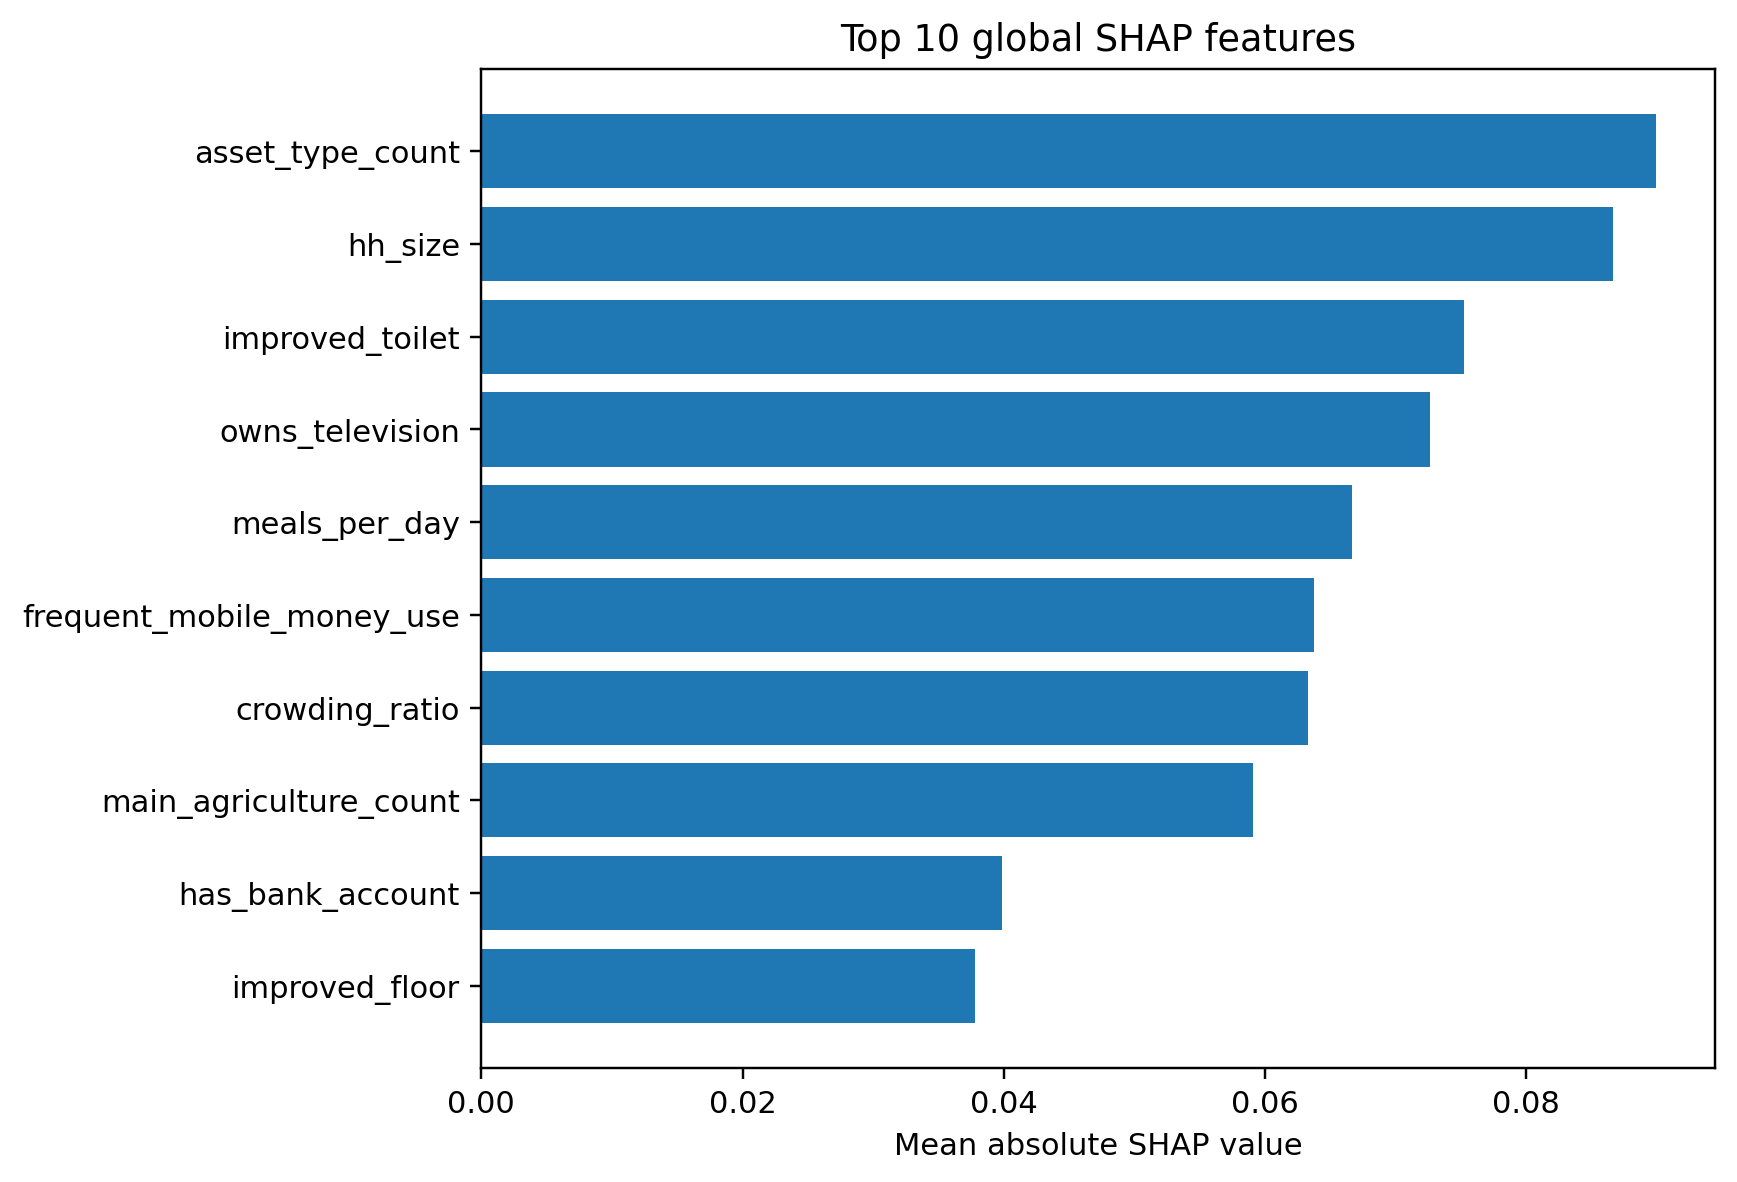

In [ ]:
final_xgb_model = clone(xgb_model).fit(X_train_imputed, y_train)
final_predictions = final_xgb_model.predict(X_test_imputed)

explainer = shap.TreeExplainer(final_xgb_model)
shap_explanation = explainer(X_test_imputed)

global_importance = (
    pd.DataFrame({
        'Feature': X_test_imputed.columns,
        'Mean absolute SHAP value': np.abs(shap_explanation.values).mean(axis=0)
    })
    .sort_values('Mean absolute SHAP value', ascending=False)
    .head(10)
)

ax = global_importance.sort_values('Mean absolute SHAP value').plot.barh(
    x='Feature', y='Mean absolute SHAP value', legend=False, figsize=(9,6)
)
ax.set_title('Top 10 global SHAP features')
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'Figure_1_Global_SHAP.png', dpi=300, bbox_inches='tight')
plt.show()


## 7. Local SHAP explainability

One publication figure combines local waterfall explanations for representative low-, middle-, and high-predicted-welfare households. Red contributions increase predicted log welfare, whereas blue contributions decrease it.


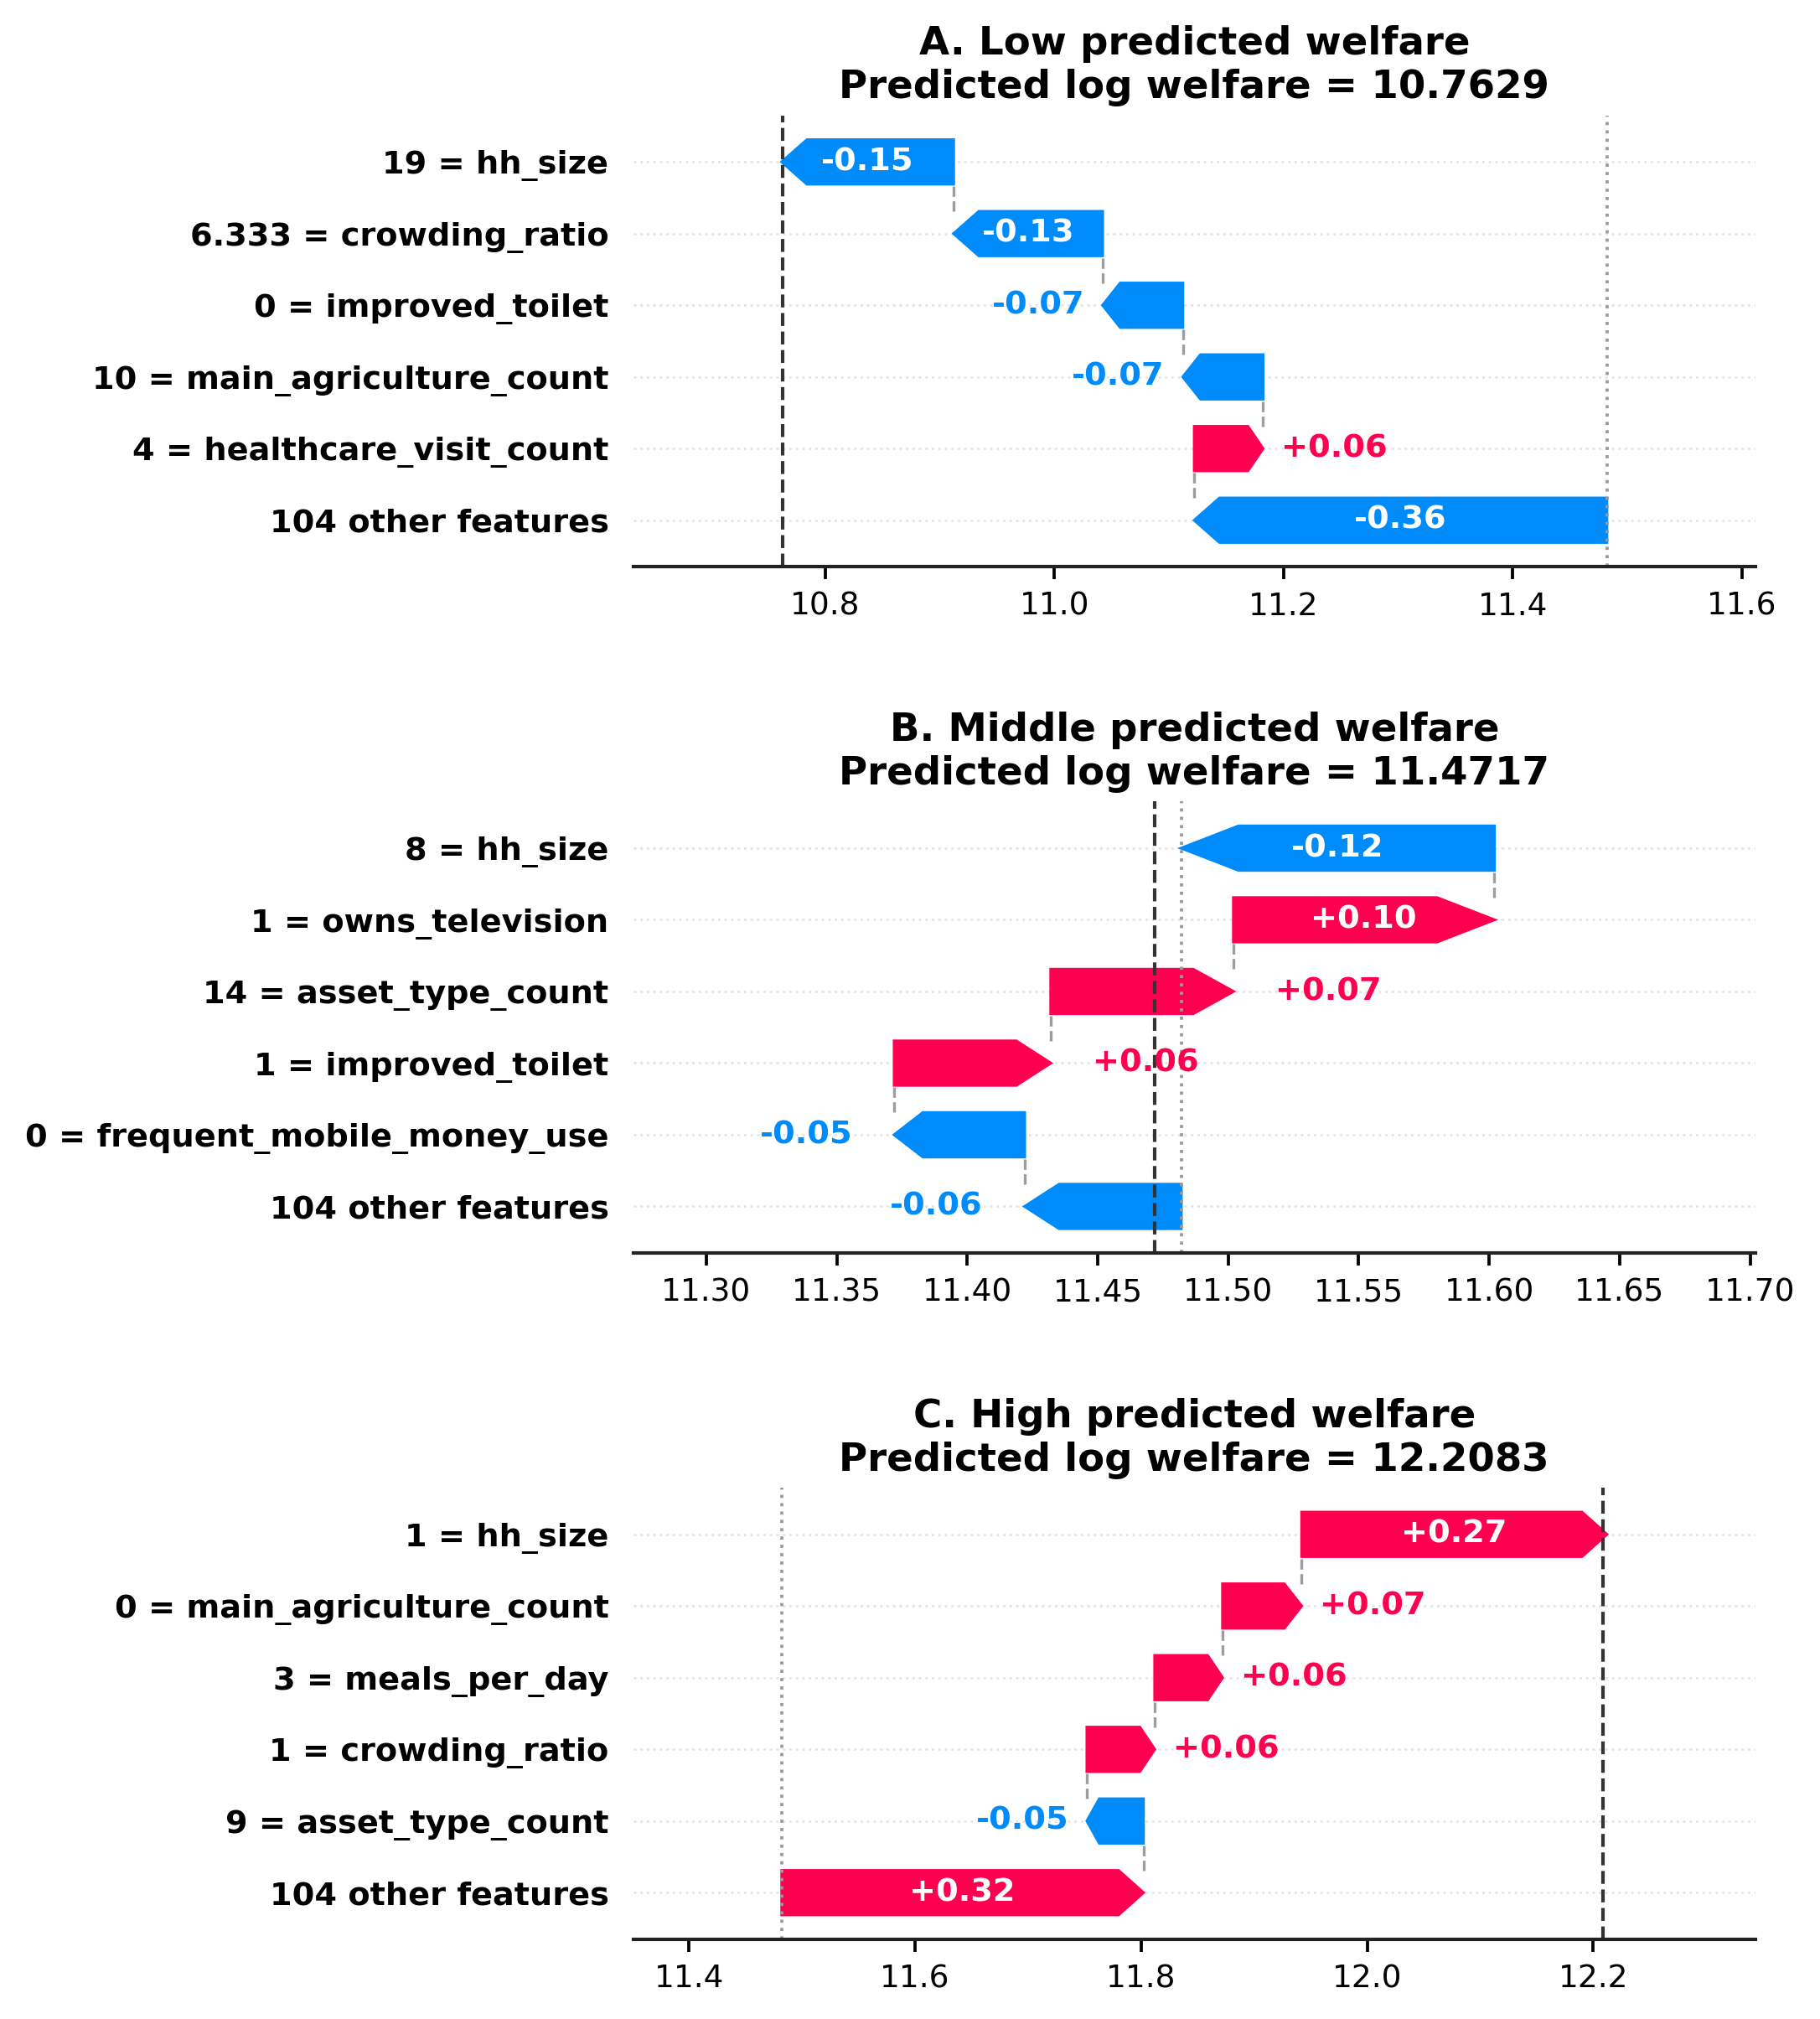

In [ ]:
from matplotlib.patches import Polygon

representative_households = {
    'A. Low predicted welfare': 4098,
    'B. Middle predicted welfare': 3398,
    'C. High predicted welfare': 2487
}

def format_feature_value(value):
    if np.isclose(value, round(value)):
        return str(int(round(value)))
    return f'{value:.3f}'.rstrip('0').rstrip('.')

def draw_shap_arrow(ax, start, end, y, value):
    colour = '#e90046' if value > 0 else '#0788e8'
    direction = 1 if end >= start else -1
    width = abs(end - start)
    head = min(width * 0.22, 0.022)
    if width < 0.025:
        head = width * 0.35
    if direction > 0:
        points = [(start,y-.31),(end-head,y-.31),(end,y),(end-head,y+.31),(start,y+.31)]
    else:
        points = [(start,y-.31),(end+head,y-.31),(end,y),(end+head,y+.31),(start,y+.31)]
    ax.add_patch(Polygon(points, closed=True, facecolor=colour, edgecolor=colour))
    inside = width >= 0.085
    ax.text((start+end)/2 if inside else end+direction*.016, y, f'{value:+.2f}',
            ha='center' if inside else ('left' if direction > 0 else 'right'),
            va='center', fontsize=9.2, fontweight='bold',
            color='white' if inside else colour)

fig, axes = plt.subplots(3, 1, figsize=(7.2, 7.8))
base_value = float(np.asarray(shap_explanation.base_values).reshape(-1)[0])

for ax, (label, household_index) in zip(axes, representative_households.items()):
    position = X_test_imputed.index.get_loc(household_index)
    contributions = shap_explanation.values[position]
    feature_values = X_test_imputed.iloc[position].to_numpy()
    top_indices = np.argsort(np.abs(contributions))[::-1][:5]
    remaining = float(contributions.sum() - contributions[top_indices].sum())

    ordered_indices = list(top_indices[::-1])
    plot_values = [remaining] + [float(contributions[i]) for i in ordered_indices]
    plot_labels = ['104 other features'] + [
        f'{format_feature_value(feature_values[i])} = {X_test_imputed.columns[i]}'
        for i in ordered_indices
    ]
    prediction = float(base_value + contributions.sum())

    starts = [base_value]
    for value in plot_values[:-1]:
        starts.append(starts[-1] + value)
    ends = [start + value for start, value in zip(starts, plot_values)]

    all_x = starts + ends + [base_value, prediction]
    xmin, xmax = min(all_x), max(all_x)
    padding = max(0.10, (xmax-xmin)*0.18)

    for y_position, (start, end, value) in enumerate(zip(starts, ends, plot_values)):
        draw_shap_arrow(ax, start, end, y_position, value)
        if y_position < len(plot_values)-1:
            ax.plot([end,end], [y_position+.31,y_position+.69], color='#999999', lw=.8, ls='--')

    ax.axvline(base_value, color='#999999', lw=.9, ls=':')
    ax.axvline(prediction, color='#333333', lw=1.0, ls='--')
    ax.set_yticks(range(len(plot_labels)))
    ax.set_yticklabels(plot_labels, fontsize=9.2, fontweight='bold')
    ax.set_xlim(xmin-padding, xmax+padding)
    ax.set_ylim(-.65, len(plot_labels)-.35)
    ax.grid(axis='y', color='#e6e6e6', linewidth=.7, linestyle=':')
    ax.tick_params(axis='y', length=0, pad=7)
    ax.set_title(f'{label}\nPredicted log welfare = {prediction:.4f}',
                 fontsize=11.2, fontweight='bold', pad=5)
    for side in ('top','right','left'):
        ax.spines[side].set_visible(False)

fig.subplots_adjust(left=.35, right=.97, top=.98, bottom=.05, hspace=.52)
plt.savefig(OUTPUT_DIR/'Figure_2_Local_SHAP_Explanations.png', dpi=300,
            bbox_inches='tight', facecolor='white')
plt.show()


## 8. Predictor sensitivity analysis

The restricted specification removes seven welfare-proximal food-security predictors. The sensitivity specification adds `income_asset_loss_shock` to the 109-predictor core specification.


In [ ]:
WELFARE_PROXIMAL = [
    'worried_about_food', 'food_coping_frequency_score', 'severe_food_deprivation',
    'meals_per_day', 'food_shortage_12m', 'food_insufficient_last_month',
    'received_food_assistance'
]

def fit_fixed_xgb(predictors):
    """Fit the prespecified XGBoost model using an alternative predictor set."""
    x = analysis_data[predictors]
    x_train = x.loc[X_train.index]
    x_test = x.loc[X_test.index]
    local_imputer = SimpleImputer(strategy='median')
    x_train = local_imputer.fit_transform(x_train)
    x_test = local_imputer.transform(x_test)
    model = clone(xgb_model).fit(x_train, y_train)
    pred = model.predict(x_test)
    return regression_metrics(y_test, pred)

restricted_predictors = [c for c in core_predictors if c not in WELFARE_PROXIMAL]
sensitivity_predictors = core_predictors + ['income_asset_loss_shock']

sensitivity_results = pd.DataFrame([
    {'Specification':'Core XGBoost (109 predictors)', **regression_metrics(y_test, final_predictions)},
    {'Specification':'Restricted XGBoost (102 predictors)', **fit_fixed_xgb(restricted_predictors)},
    {'Specification':'Sensitivity XGBoost (110 predictors)', **fit_fixed_xgb(sensitivity_predictors)}
])
sensitivity_results.round(4)


                           Specification    RMSE     MAE      R2
0          Core XGBoost (109 predictors)  0.4684  0.3528  0.5679
1    Restricted XGBoost (102 predictors)  0.4716  0.3546  0.5619
2   Sensitivity XGBoost (110 predictors)  0.4677  0.3519  0.5691


## 9. Welfare-distribution and subgroup diagnostics

Performance is evaluated across actual welfare quintiles, urban and rural households, and Tanzania Mainland and Zanzibar. Mean prediction bias is defined as predicted minus actual log welfare.


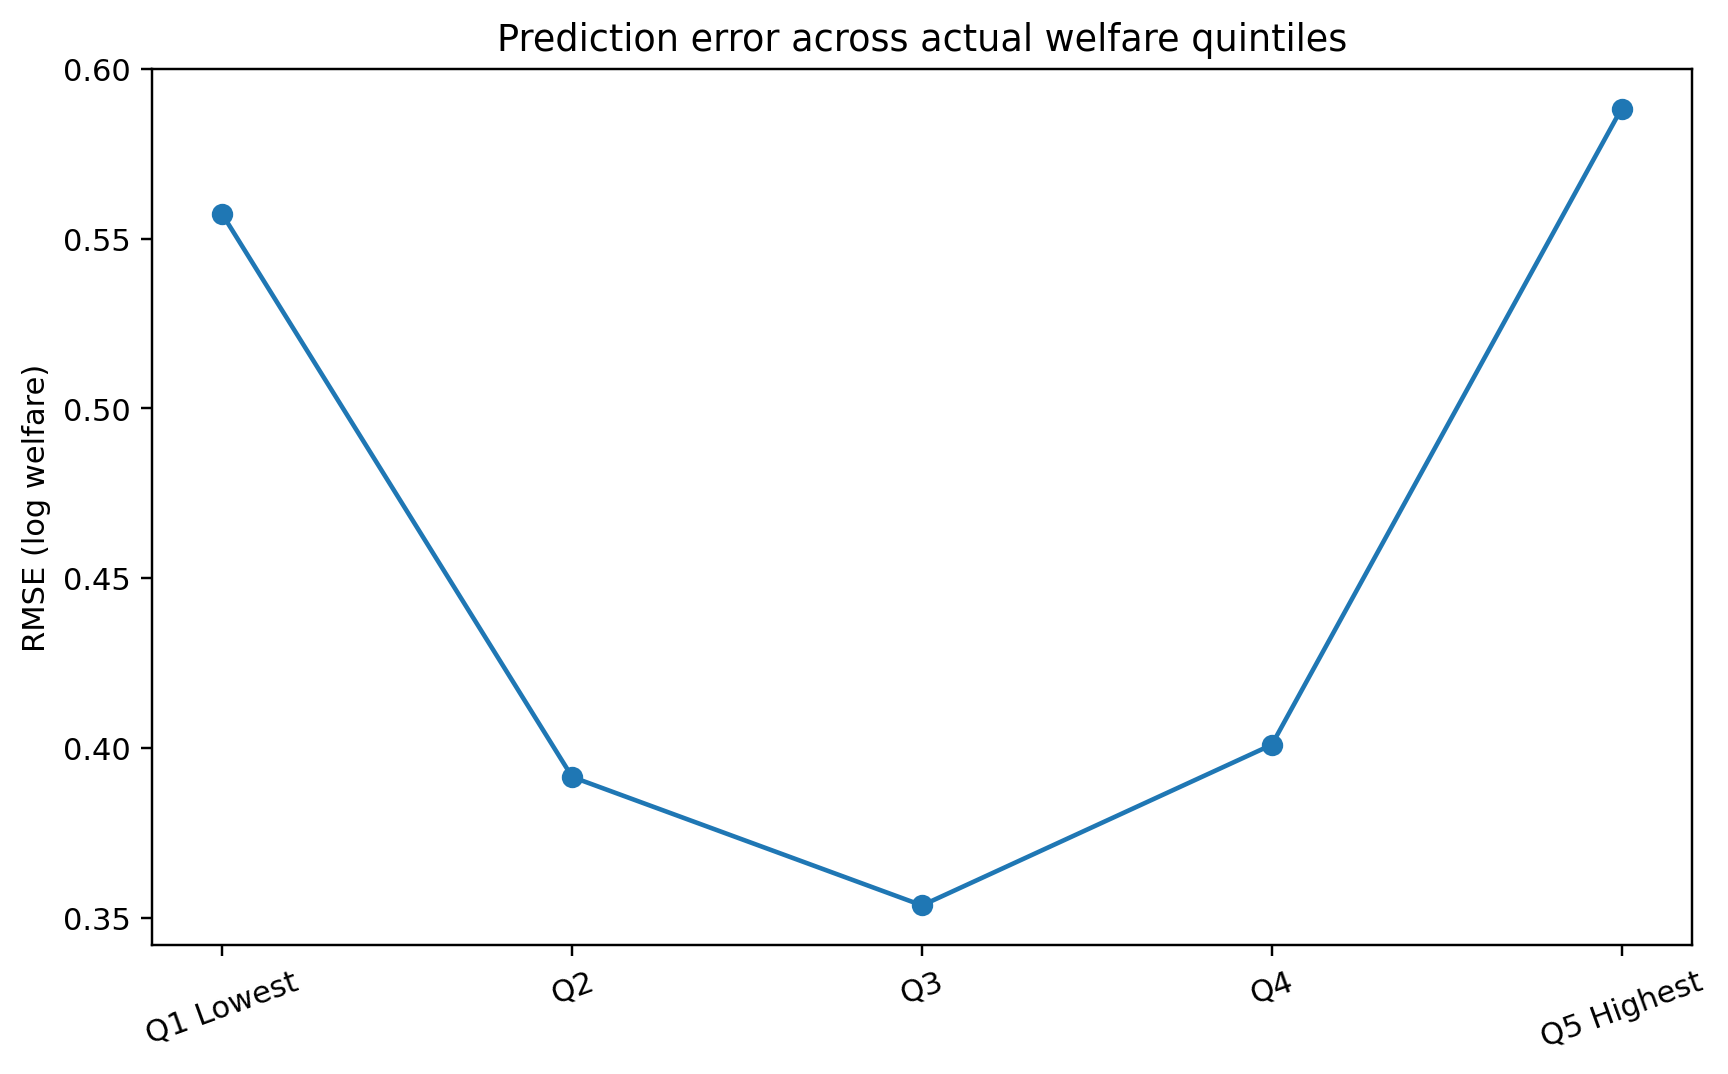

In [ ]:
diagnostics = pd.DataFrame({
    'Actual':y_test,
    'Predicted':final_predictions
}, index=y_test.index)
diagnostics['Error'] = diagnostics['Predicted'] - diagnostics['Actual']
diagnostics['Welfare quintile'] = pd.qcut(
    diagnostics['Actual'], 5,
    labels=['Q1 Lowest','Q2','Q3','Q4','Q5 Highest']
)

quintile_performance = diagnostics.groupby('Welfare quintile', observed=False).apply(
    lambda g: pd.Series({
        'N':len(g),
        'RMSE':mean_squared_error(g.Actual,g.Predicted)**0.5,
        'MAE':mean_absolute_error(g.Actual,g.Predicted),
        'Mean prediction bias':g.Error.mean()
    }), include_groups=False
).reset_index()

plt.figure(figsize=(8,5))
plt.plot(quintile_performance['Welfare quintile'], quintile_performance['RMSE'], marker='o')
plt.ylabel('RMSE (log welfare)')
plt.title('Prediction error across actual welfare quintiles')
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'Figure_3_Welfare_Quintile_Error.png', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
context = analysis_data.loc[y_test.index, ['urban','mainland']].copy()
diagnostics_context = diagnostics.join(context)

def subgroup_metrics(frame, group_var, labels):
    """Calculate performance and mean prediction bias within each subgroup."""
    rows=[]
    for value, group in frame.groupby(group_var):
        rows.append({
            'Group':labels.get(value, str(value)), 'N':len(group),
            **regression_metrics(group.Actual, group.Predicted),
            'Mean prediction bias':group.Error.mean()
        })
    return pd.DataFrame(rows)

subgroup_results = pd.concat([
    subgroup_metrics(diagnostics_context, 'urban', {0:'Rural',1:'Urban'}),
    subgroup_metrics(diagnostics_context, 'mainland', {0:'Zanzibar',1:'Mainland'})
], ignore_index=True)
subgroup_results.round(4)


       Group    N    RMSE     MAE      R2  Mean prediction bias
0      Urban  502  0.4180  0.3281  0.6420                0.0098
1      Rural  440  0.5199  0.3809  0.4849                0.0351
2   Mainland  808  0.4741  0.3528  0.5709                0.0183
3   Zanzibar  134  0.4323  0.3528  0.4831                0.0416


## 10. Survey-weighted validation

The held-out evaluation is repeated using the NPS household survey weights to assess population-relevant performance.


In [ ]:
weights = analysis_data.loc[y_test.index, 'hhweight'].astype(float).to_numpy()
actual = y_test.to_numpy()
predicted = np.asarray(final_predictions)

weighted_rmse = np.average((actual-predicted)**2, weights=weights)**0.5
weighted_mae = np.average(np.abs(actual-predicted), weights=weights)
weighted_actual_mean = np.average(actual, weights=weights)
weighted_r2 = 1 - np.sum(weights*(actual-predicted)**2) / np.sum(weights*(actual-weighted_actual_mean)**2)
weighted_bias = np.average(predicted-actual, weights=weights)

weighted_results = pd.DataFrame({
    'Metric':['RMSE','MAE','R2','Mean prediction bias'],
    'Unweighted':[0.4684,0.3528,0.5679,0.0216],
    'Survey-weighted':[weighted_rmse,weighted_mae,weighted_r2,weighted_bias]
})
weighted_results.round(4)


                 Metric  Unweighted  Survey-weighted
0                  RMSE      0.4684           0.4406
1                   MAE      0.3528           0.3390
2                    R2      0.5679           0.6059
3  Mean prediction bias      0.0216          -0.0051


## 11. Reproducibility summary

- Python version: 3.12  
- Random seed: 42  
- Training/test split: 80%/20%  
- Cross-validation: five-fold on the training data  
- Held-out households: 942  
- Main specification: 109 non-consumption predictors  
- Restricted specification: 102 predictors  
- Interpretation: global and local SHAP explanations  
- Population checks: welfare quintiles, geography, and survey-weighted evaluation

The results are predictive associations and should not be interpreted as causal effects. External and temporal validation is required before operational use in official statistics.
